# Twitter Sentiment Analysis

Loading Libraries

In [61]:
# utilities
import re
import pickle
import numpy as np
import pandas as pd
import os
from transformers.models.auto.tokenization_auto import AutoTokenizer
import matplotlib.pyplot as plt
from tqdm import tqdm

# plotting
import seaborn as sns
#from wordcloud import WordCloud
import matplotlib.pyplot as plt

# nltk
from nltk.stem import WordNetLemmatizer

# sklearn
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import BernoulliNB
from sklearn.linear_model import LogisticRegression

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import confusion_matrix, classification_report

In [62]:
tqdm.pandas()

Importing Dataset

In [63]:
train_data= pd.read_csv('train_data.csv')
test_data=pd.read_csv('test_data.csv')

## DATA ANALYSIS

In [64]:
train_data.head()

,sentence,sentiment
0,awww that s a bummer you shoulda got david car...,0
1,is upset that he can t update his facebook by ...,0
2,i dived many times for the ball managed to sav...,0
3,my whole body feels itchy and like its on fire,0
4,no it s not behaving at all i m mad why am i h...,0


In [65]:
test_data.head()

,sentence,sentiment
0,i loooooooovvvvvveee my kindle not that the dx...,1
1,reading my kindle love it lee childs is good read,1
2,ok first assesment of the kindle it fucking rocks,1
3,you ll love your kindle i ve had mine for a fe...,1
4,fair enough but i have the kindle and i think ...,1


In [66]:
train_data.shape

(1523975, 2)

In [67]:

test_data.shape

(359, 2)

Checking label counts

0    767059
1    756916
Name: sentiment, dtype: int64


<AxesSubplot:>

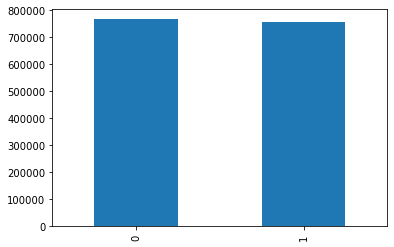

In [68]:
print(train_data['sentiment'].value_counts())
train_data['sentiment'].value_counts().plot.bar()

1    182
0    177
Name: sentiment, dtype: int64


<AxesSubplot:>

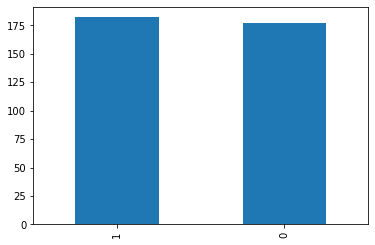

In [69]:
print(test_data['sentiment'].value_counts())
test_data['sentiment'].value_counts().plot.bar()

## Data Preprocessing

In [70]:
def process_text(text: str):
    """
    This removes
     - URLs
     - Usernames
     - Punctations (replace them with  ' ')
     - Numbers (replace them with ' ')
     - Multiple Spaces together (replace them with ' ')
    """
    text = re.sub(r'http[s]?://\S+', '', text)
    text = re.sub(r' www\S+', '', text)
    text = re.sub(r'@\S+', '', text)
    text = re.sub(r'[^\w\s]|[\d]', ' ', text)
    text = re.sub(r'\s\s+', ' ', text)
    text = text.strip().lower().encode('ascii', 'ignore').decode()
    return text

In [71]:
train_data['sentence'] = train_data['sentence'].progress_map(process_text)
test_data['sentence'] = test_data['sentence'].progress_map(process_text)
train_data.head()

100%|██████████| 359/359 [00:00<00:00, 59638.59it/s]


,sentence,sentiment
0,awww that s a bummer you shoulda got david car...,0
1,is upset that he can t update his facebook by ...,0
2,i dived many times for the ball managed to sav...,0
3,my whole body feels itchy and like its on fire,0
4,no it s not behaving at all i m mad why am i h...,0


In [72]:
test_data.head()

,sentence,sentiment
0,i loooooooovvvvvveee my kindle not that the dx...,1
1,reading my kindle love it lee childs is good read,1
2,ok first assesment of the kindle it fucking rocks,1
3,you ll love your kindle i ve had mine for a fe...,1
4,fair enough but i have the kindle and i think ...,1


Removing Blanks

In [73]:
train_data = train_data[train_data['sentence'] != ''].reset_index(drop=True)

Removing neutrals from the test data

In [74]:
test_data = test_data[test_data['sentiment'] > -1].reset_index(drop=True)

Removing Duplicates

In [75]:
print("Before")
print("Duplicates in Train Set:", train_data.duplicated().sum())
print("Duplicates in Test Set:", test_data.duplicated().sum())

print()
# There are a few duplicates in the training_set (About 16.309k)
train_data = train_data[~train_data.duplicated()].reset_index(drop=True)

print("After")
print("Duplicates in Train Set:", train_data.duplicated().sum())
print("Duplicates in Test Set:", test_data.duplicated().sum())

Before
Duplicates in Train Set: 198
Duplicates in Test Set: 0

After
Duplicates in Train Set: 0
Duplicates in Test Set: 0


Exploring the lengths of sentences

In [76]:
# Tokenizer
model_name = "distilroberta-base"
tokenizer = AutoTokenizer.from_pretrained(model_name)

In [77]:
train_data['encoded'] = train_data['sentence'].progress_map(tokenizer.encode)
train_data['lengths'] = train_data['encoded'].map(len)

test_data['encoded'] = test_data['sentence'].progress_map(tokenizer.encode)
test_data['lengths'] = test_data['encoded'].map(len)

100%|██████████| 359/359 [00:00<00:00, 5534.48it/s]


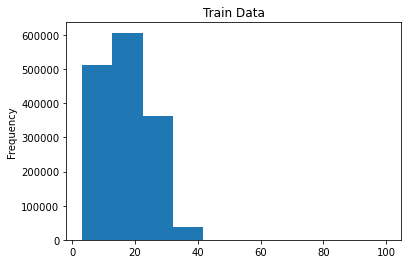

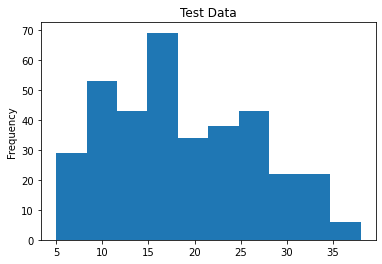

In [78]:
plt.title("Train Data")
train_data['lengths'].plot.hist()
plt.show()

plt.title("Test Data")
test_data['lengths'].plot.hist()
plt.show()

Counting UNK words

In [79]:
unk_words = sum([tokenizer.unk_token_id in encoded for encoded in train_data['encoded']])
print(f"There are {unk_words} unk words in train")

unk_words = sum([tokenizer.unk_token_id in encoded for encoded in test_data['encoded']])
print(f"There are {unk_words} unk words in test")

There are 0 unk words in train
There are 0 unk words in test


Splitting data

In [80]:
X_train = train_data['sentence']
y_train = train_data['sentiment']
X_test = test_data['sentence']
y_test = test_data['sentiment']
print(f'Data Split done.')

Data Split done.


TF-IDF Vectoriser

In [81]:
vectoriser = TfidfVectorizer(ngram_range=(1,2), max_features=500000)
vectoriser.fit(X_train)
print(f'Vectoriser fitted.')
print('No. of feature_words: ', len(vectoriser.get_feature_names()))

Vectoriser fitted.
No. of feature_words:  500000


Transforming data

In [82]:
X_train = vectoriser.transform(X_train)
X_test  = vectoriser.transform(X_test)
print(f'Data Transformed.')

Data Transformed.


## Create and Evaluate Models

Evaluation model function

In [83]:
def model_Evaluate(model):
    
    # Predict values for Test dataset
    y_pred = model.predict(X_test)

    # Print the evaluation metrics for the dataset.
    print(classification_report(y_test, y_pred))
    
    # Compute and plot the Confusion matrix
    cf_matrix = confusion_matrix(y_test, y_pred)

    categories  = ['Negative','Positive']
    group_names = ['True Neg','False Pos', 'False Neg','True Pos']
    group_percentages = ['{0:.2%}'.format(value) for value in cf_matrix.flatten() / np.sum(cf_matrix)]

    labels = [f'{v1}\n{v2}' for v1, v2 in zip(group_names,group_percentages)]
    labels = np.asarray(labels).reshape(2,2)

    sns.heatmap(cf_matrix, annot = labels, cmap = 'Blues',fmt = '',
                xticklabels = categories, yticklabels = categories)

    plt.xlabel("Predicted values", fontdict = {'size':14}, labelpad = 10)
    plt.ylabel("Actual values"   , fontdict = {'size':14}, labelpad = 10)
    plt.title ("Confusion Matrix", fontdict = {'size':18}, pad = 20)

BernoulliNB Mode

              precision    recall  f1-score   support

           0       0.85      0.80      0.83       177
           1       0.82      0.86      0.84       182

    accuracy                           0.83       359
   macro avg       0.83      0.83      0.83       359
weighted avg       0.83      0.83      0.83       359



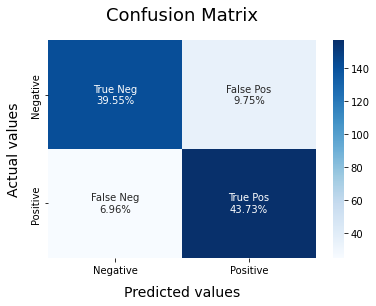

In [84]:
BNBmodel = BernoulliNB(alpha = 2)
BNBmodel.fit(X_train, y_train)
model_Evaluate(BNBmodel)

LinearSVC Model

              precision    recall  f1-score   support

           0       0.85      0.76      0.80       177
           1       0.79      0.87      0.83       182

    accuracy                           0.82       359
   macro avg       0.82      0.82      0.82       359
weighted avg       0.82      0.82      0.82       359



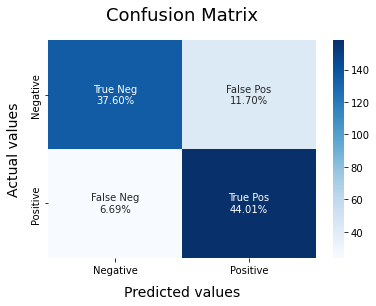

In [85]:
SVCmodel = LinearSVC()
SVCmodel.fit(X_train, y_train)
model_Evaluate(SVCmodel)

Logistic Regression Model

              precision    recall  f1-score   support

           0       0.86      0.76      0.80       177
           1       0.79      0.88      0.83       182

    accuracy                           0.82       359
   macro avg       0.82      0.82      0.82       359
weighted avg       0.82      0.82      0.82       359



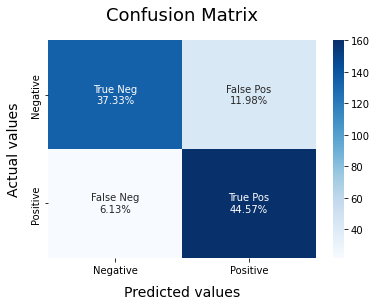

In [86]:
LRmodel = LogisticRegression(C = 2, max_iter = 1000, n_jobs=-1)
LRmodel.fit(X_train, y_train)
model_Evaluate(LRmodel)

Saving Models

In [87]:
file = open('vectoriser-ngram-(1,2).pickle','wb')
pickle.dump(vectoriser, file)
file.close()

file = open('Sentiment-LR.pickle','wb')
pickle.dump(LRmodel, file)
file.close()

file = open('Sentiment-BNB.pickle','wb')
pickle.dump(BNBmodel, file)
file.close()

Using Models

def load_models():
    
    # Load the vectoriser.
    file = open('vectoriser-ngram-(1,2).pickle', 'rb')
    vectoriser = pickle.load(file)
    file.close()
    # Load the LR Model.
    file = open('Sentiment-LRv1.pickle', 'rb')
    LRmodel = pickle.load(file)
    file.close()
    
    return vectoriser, LRmodel

def predict(vectoriser, model, text):
    # Predict the sentiment
    textdata = vectoriser.transform(process_text(text))
    sentiment = model.predict(textdata)
    
    # Make a list of text with sentiment.
    data = []
    for text, pred in zip(text, sentiment):
        data.append((text,pred))
        
    # Convert the list into a Pandas DataFrame.
    df = pd.DataFrame(data, columns = ['sentence','sentiment'])
    df = df.replace([0,1], ["Negative","Positive"])
    return df

if __name__=="__main__":
    # Loading the models.
    #vectoriser, LRmodel = load_models()
    
    # Text to classify should be in a list.
    sentence = ["I hate twitter",
            #"May the Force be with you.",
            #"Mr. Stark, I don't feel so good"]
    
    df.predict(vectoriser, LRmodel, sentence)
    #print(df.head())
df.head()

# ARTIFICIAL NEURAL NETWORKS

Importing Libraries

In [1]:
# DataFrame
import pandas as pd

# Matplot
import matplotlib.pyplot as plt
%matplotlib inline

# Scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
from sklearn.manifold import TSNE
from sklearn.feature_extraction.text import TfidfVectorizer
# Keras
from keras.preprocessing.text import Tokenizer
from keras.preprocessing.sequence import pad_sequences
from keras.models import Sequential
from keras.layers import Activation, Dense, Dropout, Embedding, Flatten, Conv1D, MaxPooling1D, LSTM
from keras import utils
from keras.callbacks import ReduceLROnPlateau, EarlyStopping

# nltk
import nltk
from nltk.corpus import stopwords
from  nltk.stem import SnowballStemmer

# Word2vec
import gensim
# Utility
import re
import numpy as np
import os
from collections import Counter
import logging
import time
import pickle
import itertools

# Set log
logging.basicConfig(format='%(asctime)s : %(levelname)s : %(message)s', level=logging.INFO)

In [2]:
nltk.download('stopwords')

[nltk_data] Error loading stopwords: <urlopen error [Errno 11001]
[nltk_data]     getaddrinfo failed>


False

Settings

In [3]:
# TEXT CLENAING
TEXT_CLEANING_RE = "@\S+|https?:\S+|http?:\S|[^A-Za-z0-9]+"

# WORD2VEC 
W2V_SIZE = 300
W2V_WINDOW = 7
W2V_EPOCH = 10
W2V_MIN_COUNT = 10
# KERAS
SEQUENCE_LENGTH = 300
EPOCHS = 1
BATCH_SIZE = 1024

# SENTIMENT
POSITIVE = "POSITIVE"
NEGATIVE = "NEGATIVE"
NEUTRAL = "NEUTRAL"
SENTIMENT_THRESHOLDS = (0.4, 0.7)

# EXPORT
KERAS_MODEL = "model.h5"
WORD2VEC_MODEL = "model.w2v"
TOKENIZER_MODEL = "tokenizer.pkl"
ENCODER_MODEL = "encoder.pkl"

Import Data

In [4]:
twitter_train = pd.read_csv('train_data.csv')
twitter_test = pd.read_csv('test_data.csv')
twitter_train.head()

,sentence,sentiment
0,awww that s a bummer you shoulda got david car...,0
1,is upset that he can t update his facebook by ...,0
2,i dived many times for the ball managed to sav...,0
3,my whole body feels itchy and like its on fire,0
4,no it s not behaving at all i m mad why am i h...,0


In [5]:
twitter_test.head()

,sentence,sentiment
0,i loooooooovvvvvveee my kindle not that the dx...,1
1,reading my kindle love it lee childs is good read,1
2,ok first assesment of the kindle it fucking rocks,1
3,you ll love your kindle i ve had mine for a fe...,1
4,fair enough but i have the kindle and i think ...,1


Map sentiment label to string

In [6]:
decode_map = {0: "NEGATIVE", 2: "NEUTRAL", 1: "POSITIVE"}
def decode_sentiment(label):
    return decode_map[int(label)]

In [7]:
%%time
twitter_train.sentiment = twitter_train.sentiment.apply(lambda x: decode_sentiment(x))
twitter_train.head()

Wall time: 849 ms


,sentence,sentiment
0,awww that s a bummer you shoulda got david car...,NEGATIVE
1,is upset that he can t update his facebook by ...,NEGATIVE
2,i dived many times for the ball managed to sav...,NEGATIVE
3,my whole body feels itchy and like its on fire,NEGATIVE
4,no it s not behaving at all i m mad why am i h...,NEGATIVE


In [8]:
%%time
twitter_test.sentiment = twitter_test.sentiment.apply(lambda x: decode_sentiment(x))
twitter_test.head()

Wall time: 997 µs


,sentence,sentiment
0,i loooooooovvvvvveee my kindle not that the dx...,POSITIVE
1,reading my kindle love it lee childs is good read,POSITIVE
2,ok first assesment of the kindle it fucking rocks,POSITIVE
3,you ll love your kindle i ve had mine for a fe...,POSITIVE
4,fair enough but i have the kindle and i think ...,POSITIVE


Preprocess data

In [9]:
stop_words = stopwords.words("english")
stemmer = SnowballStemmer("english")

In [10]:
def preprocess(text, stem=False):
    # Remove link,user and special characters
    text = re.sub(TEXT_CLEANING_RE, ' ', str(text).lower()).strip()
    tokens = []
    for token in text.split():
        if token not in stop_words:
            if stem:
                tokens.append(stemmer.stem(token))
            else:
                tokens.append(token)
    return " ".join(tokens)

In [11]:
%%time
twitter_train.sentiment = twitter_train.sentiment.apply(lambda x: preprocess(x))

Wall time: 15.1 s


In [12]:
%%time
twitter_test.sentiment = twitter_test.sentiment.apply(lambda x: preprocess(x))

Wall time: 4.02 ms


In [13]:
print("TRAIN size:", len(twitter_train))
print("TEST size:", len(twitter_test))

TRAIN size: 1523975
TEST size: 359


Word2Vec

In [14]:
%%time
documents = [_text.split() for _text in twitter_train.sentence]

Wall time: 7.95 s


In [15]:
w2v_model = gensim.models.word2vec.Word2Vec(vector_size=W2V_SIZE, 
                                            window=W2V_WINDOW, 
                                            min_count=W2V_MIN_COUNT, 
                                            workers=50)

2022-04-28 22:59:54,579 : INFO : Word2Vec lifecycle event {'params': 'Word2Vec(vocab=0, vector_size=300, alpha=0.025)', 'datetime': '2022-04-28T22:59:54.579527', 'gensim': '4.1.2', 'python': '3.9.7 (default, Sep 16 2021, 16:59:28) [MSC v.1916 64 bit (AMD64)]', 'platform': 'Windows-10-10.0.22000-SP0', 'event': 'created'}


In [16]:
w2v_model.build_vocab(documents)

2022-04-28 23:00:00,619 : INFO : collecting all words and their counts
2022-04-28 23:00:00,621 : INFO : PROGRESS: at sentence #0, processed 0 words, keeping 0 word types
2022-04-28 23:00:00,665 : INFO : PROGRESS: at sentence #10000, processed 136454 words, keeping 12553 word types
2022-04-28 23:00:00,729 : INFO : PROGRESS: at sentence #20000, processed 271800 words, keeping 18833 word types
2022-04-28 23:00:00,793 : INFO : PROGRESS: at sentence #30000, processed 406616 words, keeping 23881 word types
2022-04-28 23:00:00,856 : INFO : PROGRESS: at sentence #40000, processed 543605 words, keeping 28262 word types
2022-04-28 23:00:00,928 : INFO : PROGRESS: at sentence #50000, processed 682724 words, keeping 32470 word types
2022-04-28 23:00:00,991 : INFO : PROGRESS: at sentence #60000, processed 819727 words, keeping 36137 word types
2022-04-28 23:00:01,053 : INFO : PROGRESS: at sentence #70000, processed 955908 words, keeping 39300 word types
2022-04-28 23:00:01,109 : INFO : PROGRESS: at 

2022-04-28 23:00:05,833 : INFO : PROGRESS: at sentence #720000, processed 10011606 words, keeping 158113 word types
2022-04-28 23:00:05,909 : INFO : PROGRESS: at sentence #730000, processed 10152151 words, keeping 159326 word types
2022-04-28 23:00:05,987 : INFO : PROGRESS: at sentence #740000, processed 10292438 words, keeping 160640 word types
2022-04-28 23:00:06,053 : INFO : PROGRESS: at sentence #750000, processed 10432377 words, keeping 162067 word types
2022-04-28 23:00:06,124 : INFO : PROGRESS: at sentence #760000, processed 10574948 words, keeping 163587 word types
2022-04-28 23:00:06,186 : INFO : PROGRESS: at sentence #770000, processed 10711352 words, keeping 165001 word types
2022-04-28 23:00:06,244 : INFO : PROGRESS: at sentence #780000, processed 10839710 words, keeping 166667 word types
2022-04-28 23:00:06,308 : INFO : PROGRESS: at sentence #790000, processed 10964092 words, keeping 168153 word types
2022-04-28 23:00:06,379 : INFO : PROGRESS: at sentence #800000, processe

2022-04-28 23:00:10,501 : INFO : PROGRESS: at sentence #1430000, processed 19201183 words, keeping 255280 word types
2022-04-28 23:00:10,595 : INFO : PROGRESS: at sentence #1440000, processed 19329193 words, keeping 256420 word types
2022-04-28 23:00:10,664 : INFO : PROGRESS: at sentence #1450000, processed 19458503 words, keeping 257847 word types
2022-04-28 23:00:10,764 : INFO : PROGRESS: at sentence #1460000, processed 19589054 words, keeping 259138 word types
2022-04-28 23:00:10,850 : INFO : PROGRESS: at sentence #1470000, processed 19718755 words, keeping 260314 word types
2022-04-28 23:00:10,927 : INFO : PROGRESS: at sentence #1480000, processed 19847323 words, keeping 261450 word types
2022-04-28 23:00:11,010 : INFO : PROGRESS: at sentence #1490000, processed 19975534 words, keeping 262583 word types
2022-04-28 23:00:11,081 : INFO : PROGRESS: at sentence #1500000, processed 20105672 words, keeping 263687 word types
2022-04-28 23:00:11,151 : INFO : PROGRESS: at sentence #1510000,

In [17]:
words = list(w2v_model.wv.key_to_index.keys())
vocab_size = len(words)
print("Vocab size", vocab_size)

Vocab size 33070


In [18]:
%%time
w2v_model.train(documents, total_examples=len(documents), epochs=W2V_EPOCH)

2022-04-28 23:00:20,611 : INFO : Word2Vec lifecycle event {'msg': 'training model with 50 workers on 33070 vocabulary and 300 features, using sg=0 hs=0 sample=0.001 negative=5 window=7 shrink_windows=True', 'datetime': '2022-04-28T23:00:20.611241', 'gensim': '4.1.2', 'python': '3.9.7 (default, Sep 16 2021, 16:59:28) [MSC v.1916 64 bit (AMD64)]', 'platform': 'Windows-10-10.0.22000-SP0', 'event': 'train'}
2022-04-28 23:00:21,890 : INFO : EPOCH 1 - PROGRESS: at 0.43% examples, 54860 words/s, in_qsize 98, out_qsize 16
2022-04-28 23:00:22,899 : INFO : EPOCH 1 - PROGRESS: at 4.12% examples, 288990 words/s, in_qsize 99, out_qsize 0
2022-04-28 23:00:24,007 : INFO : EPOCH 1 - PROGRESS: at 6.65% examples, 312193 words/s, in_qsize 100, out_qsize 5
2022-04-28 23:00:25,077 : INFO : EPOCH 1 - PROGRESS: at 9.48% examples, 338726 words/s, in_qsize 94, out_qsize 5
2022-04-28 23:00:26,086 : INFO : EPOCH 1 - PROGRESS: at 12.87% examples, 375188 words/s, in_qsize 97, out_qsize 2
2022-04-28 23:00:27,248 : 

2022-04-28 23:00:57,396 : INFO : worker thread finished; awaiting finish of 6 more threads
2022-04-28 23:00:57,414 : INFO : worker thread finished; awaiting finish of 5 more threads
2022-04-28 23:00:57,421 : INFO : worker thread finished; awaiting finish of 4 more threads
2022-04-28 23:00:57,422 : INFO : worker thread finished; awaiting finish of 3 more threads
2022-04-28 23:00:57,427 : INFO : worker thread finished; awaiting finish of 2 more threads
2022-04-28 23:00:57,427 : INFO : worker thread finished; awaiting finish of 1 more threads
2022-04-28 23:00:57,442 : INFO : worker thread finished; awaiting finish of 0 more threads
2022-04-28 23:00:57,444 : INFO : EPOCH - 1 : training on 20417999 raw words (15390005 effective words) took 36.8s, 418444 effective words/s
2022-04-28 23:00:58,559 : INFO : EPOCH 2 - PROGRESS: at 0.48% examples, 71788 words/s, in_qsize 72, out_qsize 27
2022-04-28 23:00:59,579 : INFO : EPOCH 2 - PROGRESS: at 3.66% examples, 276642 words/s, in_qsize 95, out_qsize

2022-04-28 23:01:34,784 : INFO : worker thread finished; awaiting finish of 10 more threads
2022-04-28 23:01:34,789 : INFO : worker thread finished; awaiting finish of 9 more threads
2022-04-28 23:01:34,795 : INFO : worker thread finished; awaiting finish of 8 more threads
2022-04-28 23:01:34,813 : INFO : worker thread finished; awaiting finish of 7 more threads
2022-04-28 23:01:34,821 : INFO : worker thread finished; awaiting finish of 6 more threads
2022-04-28 23:01:34,834 : INFO : worker thread finished; awaiting finish of 5 more threads
2022-04-28 23:01:34,841 : INFO : worker thread finished; awaiting finish of 4 more threads
2022-04-28 23:01:34,847 : INFO : worker thread finished; awaiting finish of 3 more threads
2022-04-28 23:01:34,851 : INFO : worker thread finished; awaiting finish of 2 more threads
2022-04-28 23:01:34,859 : INFO : worker thread finished; awaiting finish of 1 more threads
2022-04-28 23:01:34,862 : INFO : worker thread finished; awaiting finish of 0 more thread

2022-04-28 23:02:11,727 : INFO : worker thread finished; awaiting finish of 14 more threads
2022-04-28 23:02:11,733 : INFO : worker thread finished; awaiting finish of 13 more threads
2022-04-28 23:02:11,738 : INFO : worker thread finished; awaiting finish of 12 more threads
2022-04-28 23:02:11,738 : INFO : worker thread finished; awaiting finish of 11 more threads
2022-04-28 23:02:11,741 : INFO : worker thread finished; awaiting finish of 10 more threads
2022-04-28 23:02:11,758 : INFO : worker thread finished; awaiting finish of 9 more threads
2022-04-28 23:02:11,760 : INFO : worker thread finished; awaiting finish of 8 more threads
2022-04-28 23:02:11,766 : INFO : worker thread finished; awaiting finish of 7 more threads
2022-04-28 23:02:11,771 : INFO : worker thread finished; awaiting finish of 6 more threads
2022-04-28 23:02:11,782 : INFO : worker thread finished; awaiting finish of 5 more threads
2022-04-28 23:02:11,792 : INFO : worker thread finished; awaiting finish of 4 more th

2022-04-28 23:02:48,036 : INFO : worker thread finished; awaiting finish of 19 more threads
2022-04-28 23:02:48,037 : INFO : worker thread finished; awaiting finish of 18 more threads
2022-04-28 23:02:48,039 : INFO : worker thread finished; awaiting finish of 17 more threads
2022-04-28 23:02:48,041 : INFO : worker thread finished; awaiting finish of 16 more threads
2022-04-28 23:02:48,042 : INFO : worker thread finished; awaiting finish of 15 more threads
2022-04-28 23:02:48,043 : INFO : worker thread finished; awaiting finish of 14 more threads
2022-04-28 23:02:48,045 : INFO : worker thread finished; awaiting finish of 13 more threads
2022-04-28 23:02:48,046 : INFO : worker thread finished; awaiting finish of 12 more threads
2022-04-28 23:02:48,047 : INFO : worker thread finished; awaiting finish of 11 more threads
2022-04-28 23:02:48,048 : INFO : worker thread finished; awaiting finish of 10 more threads
2022-04-28 23:02:48,051 : INFO : worker thread finished; awaiting finish of 9 mo

2022-04-28 23:03:24,185 : INFO : worker thread finished; awaiting finish of 22 more threads
2022-04-28 23:03:24,193 : INFO : worker thread finished; awaiting finish of 21 more threads
2022-04-28 23:03:24,209 : INFO : worker thread finished; awaiting finish of 20 more threads
2022-04-28 23:03:24,211 : INFO : worker thread finished; awaiting finish of 19 more threads
2022-04-28 23:03:24,234 : INFO : worker thread finished; awaiting finish of 18 more threads
2022-04-28 23:03:24,236 : INFO : worker thread finished; awaiting finish of 17 more threads
2022-04-28 23:03:24,237 : INFO : worker thread finished; awaiting finish of 16 more threads
2022-04-28 23:03:24,239 : INFO : worker thread finished; awaiting finish of 15 more threads
2022-04-28 23:03:24,241 : INFO : worker thread finished; awaiting finish of 14 more threads
2022-04-28 23:03:24,255 : INFO : worker thread finished; awaiting finish of 13 more threads
2022-04-28 23:03:24,258 : INFO : worker thread finished; awaiting finish of 12 m

... (3 outputs left out)

2022-04-28 23:05:50,382 : INFO : worker thread finished; awaiting finish of 36 more threads
2022-04-28 23:05:50,393 : INFO : worker thread finished; awaiting finish of 35 more threads
2022-04-28 23:05:50,411 : INFO : worker thread finished; awaiting finish of 34 more threads
2022-04-28 23:05:50,419 : INFO : EPOCH 9 - PROGRESS: at 98.34% examples, 424207 words/s, in_qsize 33, out_qsize 1
2022-04-28 23:05:50,420 : INFO : worker thread finished; awaiting finish of 33 more threads
2022-04-28 23:05:50,422 : INFO : worker thread finished; awaiting finish of 32 more threads
2022-04-28 23:05:50,425 : INFO : worker thread finished; awaiting finish of 31 more threads
2022-04-28 23:05:50,462 : INFO : worker thread finished; awaiting finish of 30 more threads
2022-04-28 23:05:50,464 : INFO : worker thread finished; awaiting finish of 29 more threads
2022-04-28 23:05:50,466 : INFO : worker thread finished; awaiting finish of 28 more threads
2022-04-28 23:05:50,467 : INFO : worker thread finished; a

2022-04-28 23:06:27,012 : INFO : worker thread finished; awaiting finish of 40 more threads
2022-04-28 23:06:27,014 : INFO : worker thread finished; awaiting finish of 39 more threads
2022-04-28 23:06:27,030 : INFO : worker thread finished; awaiting finish of 38 more threads
2022-04-28 23:06:27,033 : INFO : worker thread finished; awaiting finish of 37 more threads
2022-04-28 23:06:27,043 : INFO : worker thread finished; awaiting finish of 36 more threads
2022-04-28 23:06:27,054 : INFO : worker thread finished; awaiting finish of 35 more threads
2022-04-28 23:06:27,058 : INFO : worker thread finished; awaiting finish of 34 more threads
2022-04-28 23:06:27,155 : INFO : worker thread finished; awaiting finish of 33 more threads
2022-04-28 23:06:27,176 : INFO : worker thread finished; awaiting finish of 32 more threads
2022-04-28 23:06:27,190 : INFO : worker thread finished; awaiting finish of 31 more threads
2022-04-28 23:06:27,268 : INFO : worker thread finished; awaiting finish of 30 m

Wall time: 6min 6s


(153912117, 204179990)

In [19]:
w2v_model.wv.most_similar("love")

[('adore', 0.7138015031814575),
 ('loooove', 0.6634089946746826),
 ('luv', 0.6513742208480835),
 ('looove', 0.6513687968254089),
 ('lovee', 0.6227790117263794),
 ('loveee', 0.6221073865890503),
 ('loove', 0.6091379523277283),
 ('loveeee', 0.5713930726051331),
 ('miss', 0.558901846408844),
 ('loved', 0.5565851926803589)]

Tokenize Text

In [20]:
%%time
tokenizer = Tokenizer()
tokenizer.fit_on_texts(twitter_train.sentence)

vocab_size = len(tokenizer.word_index) + 1
print("Total words", vocab_size)

Total words 265770
Wall time: 59.6 s


In [21]:
%%time
x_train = pad_sequences(tokenizer.texts_to_sequences(twitter_train.sentence), maxlen=SEQUENCE_LENGTH)
x_test = pad_sequences(tokenizer.texts_to_sequences(twitter_test.sentence), maxlen=SEQUENCE_LENGTH)

Wall time: 1min 1s


Label Encoder

In [22]:
labels = twitter_train.sentiment.unique().tolist()
labels.append(NEUTRAL)
labels

['negative', 'positive', 'NEUTRAL']

In [23]:
encoder = LabelEncoder()
encoder.fit(twitter_train.sentiment.tolist())

y_train = encoder.transform(twitter_train.sentiment.tolist())
y_test = encoder.transform(twitter_test.sentiment.tolist())

y_train = y_train.reshape(-1,1)
y_test = y_test.reshape(-1,1)

print("y_train",y_train.shape)
print("y_test",y_test.shape)

y_train (1523975, 1)
y_test (359, 1)


In [24]:
print("x_train", x_train.shape)
print("y_train", y_train.shape)
print()
print("x_test", x_test.shape)
print("y_test", y_test.shape)

x_train (1523975, 300)
y_train (1523975, 1)

x_test (359, 300)
y_test (359, 1)


In [25]:
y_train[:10]

array([[0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0]])

Embedding layer

In [26]:
embedding_matrix = np.zeros((vocab_size, W2V_SIZE))
for word, i in tokenizer.word_index.items():
  if word in w2v_model.wv:
    embedding_matrix[i] = w2v_model.wv[word]
print(embedding_matrix.shape)

(265770, 300)


In [27]:
embedding_layer = Embedding(vocab_size, W2V_SIZE, 
weights=[embedding_matrix], input_length=SEQUENCE_LENGTH, trainable=False)

Build Model

In [28]:
model = Sequential()
model.add(embedding_layer)
model.add(Dropout(0.5))
model.add(LSTM(100, dropout=0.2, recurrent_dropout=0.2))
model.add(Dense(1, activation='sigmoid'))

model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding (Embedding)       (None, 300, 300)          79731000  
                                                                 
 dropout (Dropout)           (None, 300, 300)          0         
                                                                 
 lstm (LSTM)                 (None, 100)               160400    
                                                                 
 dense (Dense)               (None, 1)                 101       
                                                                 
Total params: 79,891,501
Trainable params: 160,501
Non-trainable params: 79,731,000
_________________________________________________________________


Compile Model

In [29]:
model.compile(loss='binary_crossentropy',
              optimizer="adam",
              metrics=['accuracy'])

Callbacks

In [30]:
callbacks = [ ReduceLROnPlateau(monitor='val_loss', patience=5, cooldown=0),
              EarlyStopping(monitor='val_acc', min_delta=1e-4, patience=5)]

Train Model

In [31]:
%%time
history = model.fit(x_train, y_train,
                    batch_size=BATCH_SIZE,
                    epochs=EPOCHS,
                    validation_split=0.1,
                    verbose=1,
                    callbacks=callbacks)

1340/1340 [==============================] - ETA: 0s - loss: 0.4861 - accuracy: 0.7649 WARNING:tensorflow:Early stopping conditioned on metric `val_acc` which is not available. Available metrics are: loss,accuracy,val_loss,val_accuracy,lr


2022-04-29 07:18:13,029 : WARNING : Early stopping conditioned on metric `val_acc` which is not available. Available metrics are: loss,accuracy,val_loss,val_accuracy,lr


1340/1340 [==============================] - 29340s 22s/step - loss: 0.4861 - accuracy: 0.7649 - val_loss: 0.5107 - val_accuracy: 0.7635 - lr: 0.0010
Wall time: 8h 9min


Evaluate Model

In [32]:
%%time
score = model.evaluate(x_test, y_test, batch_size=BATCH_SIZE)
print()
print("ACCURACY:",score[1])
print("LOSS:",score[0])

1/1 [==============================] - 3s 3s/step - loss: 0.3909 - accuracy: 0.8106

ACCURACY: 0.8105849623680115
LOSS: 0.39088597893714905
Wall time: 2.72 s


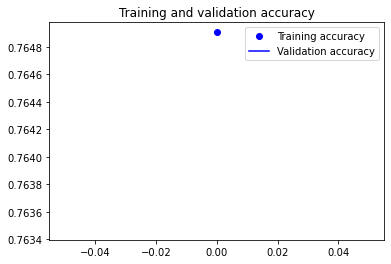

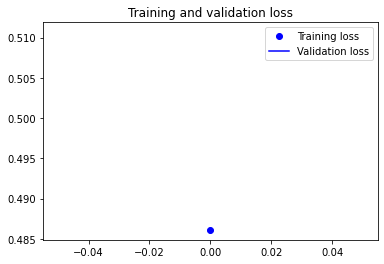

In [54]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
 
epochs = range(len(acc))
plt.plot(epochs, acc, 'bo', label='Training accuracy')
plt.plot(epochs, val_acc, 'b', label='Validation accuracy')
plt.title('Training and validation accuracy')
plt.legend()
plt.figure()
plt.plot(epochs, loss, 'bo', label='Training loss')
plt.plot(epochs, val_loss, 'b', label='Validation loss')
plt.title('Training and validation loss')
plt.legend()
plt.show()

Predict

In [55]:
def decode_sentiment(score, include_neutral=True):
    if include_neutral:        
        label = NEUTRAL
        if score <= SENTIMENT_THRESHOLDS[0]:
            label = NEGATIVE
        elif score >= SENTIMENT_THRESHOLDS[1]:
            label = POSITIVE

        return label
    else:
        return NEGATIVE if score < 0.5 else POSITIVE

In [56]:
def predict(text, include_neutral=True):
    start_at = time.time()
    # Tokenize text
    x_test = pad_sequences(tokenizer.texts_to_sequences([text]), maxlen=SEQUENCE_LENGTH)
    # Predict
    score = model.predict([x_test])[0]
    # Decode sentiment
    label = decode_sentiment(score, include_neutral=include_neutral)

    return {"label": label, "score": float(score),
       "elapsed_time": time.time()-start_at}

In [57]:
predict("I love the music")

{'label': 'POSITIVE',
 'score': 0.9857774972915649,
 'elapsed_time': 0.14461326599121094}

In [58]:
predict("i'm not your friend")

{'label': 'NEGATIVE',
 'score': 0.17466309666633606,
 'elapsed_time': 0.14411616325378418}

In [59]:
predict("i don't know what i'm doing")

{'label': 'NEUTRAL',
 'score': 0.5732851624488831,
 'elapsed_time': 0.13164758682250977}

Save model

In [60]:
file = open('Sentiment-LSTM.pickle','wb')
pickle.dump(history, file)
file.close()

INFO:tensorflow:Assets written to: ram://f9842596-49c4-4f6e-a331-01d26cbd8b45/assets


2022-04-29 07:42:58,894 : INFO : Assets written to: ram://f9842596-49c4-4f6e-a331-01d26cbd8b45/assets
2022-04-29 07:43:00,405 : WARNING : <keras.layers.recurrent.LSTMCell object at 0x0000029B8C171970> has the same name 'LSTMCell' as a built-in Keras object. Consider renaming <class 'keras.layers.recurrent.LSTMCell'> to avoid naming conflicts when loading with `tf.keras.models.load_model`. If renaming is not possible, pass the object in the `custom_objects` parameter of the load function.
